# 06 - PCA and Dimensionality Reduction
### Credit Portfolio Segmentation and Risk Pattern Analysis

---

## Visualizing High-Dimensional Data with PCA
We are tracking 5 financial dimensions simultaneously. While algorithms calculate distances across 5 dimensions without difficulty, human charts can only display 2D or 3D views.

**Principal Component Analysis (PCA)** combines correlated variables into orthogonal components:
- It keeps the maximum possible portfolio variance.
- It allows us to view borrower distributions and clusters on a 2D scatter plot.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

X_scaled = pd.read_csv("../data/processed/scaled_features.csv")
df_clean = pd.read_csv("../data/processed/cleaned_loans_dataset.csv")

print(f"Loaded {X_scaled.shape[1]} features across {X_scaled.shape[0]:,} borrowers.")


Loaded 5 features across 25,000 borrowers.


---
## 1. Fitting PCA with 2 Components
Let's see how much information 2 principal components capture.


In [2]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df_clean['PC1'] = X_pca[:, 0]
df_clean['PC2'] = X_pca[:, 1]

var_ratio = pca.explained_variance_ratio_
print(f"PC1 explains: {var_ratio[0]*100:.2f}% of variance")
print(f"PC2 explains: {var_ratio[1]*100:.2f}% of variance")
print(f"Total variance retained in 2D: {var_ratio.sum()*100:.2f}%")


PC1 explains: 32.04% of variance
PC2 explains: 21.43% of variance
Total variance retained in 2D: 53.47%


---
## 2. Scree Plot: Component Variance Coverage
Let's plot the cumulative explained variance across all 5 possible components.


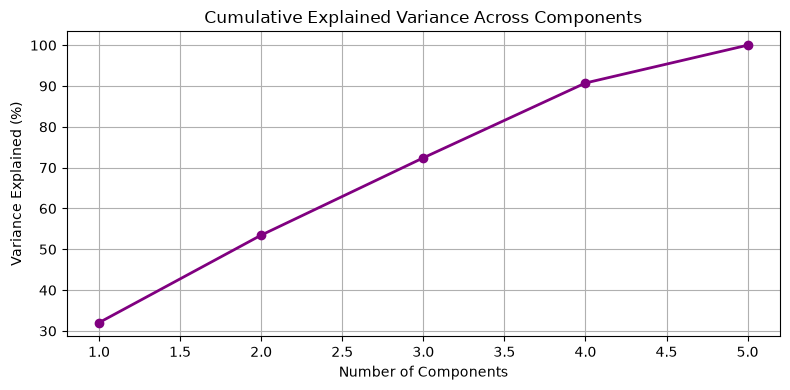

In [3]:
pca_full = PCA(n_components=5, random_state=42)
pca_full.fit(X_scaled)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 6), np.cumsum(pca_full.explained_variance_ratio_) * 100, marker='o', color='purple', linewidth=2)
plt.title("Cumulative Explained Variance Across Components")
plt.xlabel("Number of Components")
plt.ylabel("Variance Explained (%)")
plt.grid(True)

plt.tight_layout()
plt.savefig("../outputs/figures/pca_scree_plot.png", dpi=300)
plt.show()


---
## 3. Projecting the Portfolio in 2D Space


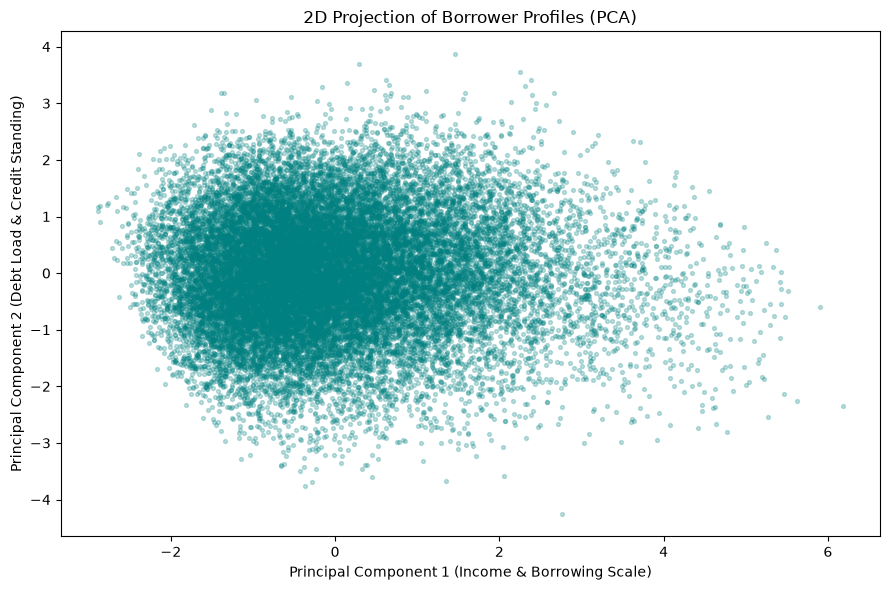

In [4]:
plt.figure(figsize=(9, 6))
plt.scatter(df_clean['PC1'], df_clean['PC2'], alpha=0.25, c='teal', s=8)
plt.title("2D Projection of Borrower Profiles (PCA)")
plt.xlabel("Principal Component 1 (Income & Borrowing Scale)")
plt.ylabel("Principal Component 2 (Debt Load & Credit Standing)")

plt.tight_layout()
plt.savefig("../outputs/figures/pca_borrower_scatter.png", dpi=300)
plt.show()
